Q5

# سوال ۵: حل پازل با الگوریتم ژنتیک (Genetic Algorithm)

در این بخش، هدف بازسازی یک تصویر به‌هم‌ریخته (پازل) با استفاده از الگوریتم ژنتیک است.
ما از کتابخانه `gaps` به عنوان هسته اصلی استفاده می‌کنیم اما توابع کلیدی (Fitness و Selection) را خودمان پیاده‌سازی و تزریق می‌کنیم تا تأثیر آن‌ها را مقایسه کنیم.

**مراحل:**
1.  آماده‌سازی تصویر و تبدیل آن به قطعات پازل.
2.  تعریف دو تابع برازش متفاوت (L1 و L2).
3.  تعریف دو روش انتخاب متفاوت (Roulette و Tournament).
4.  اجرای ۴ آزمایش موازی و مقایسه نتایج.

Core 'gaps' modules loaded successfully.
Puzzle Configuration: 8 rows x 8 columns (Total: 64 pieces)


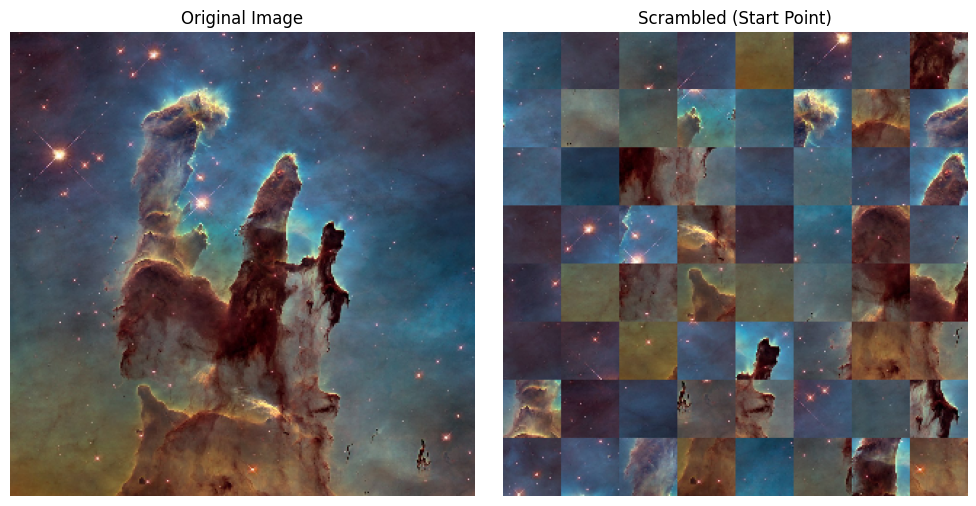

In [36]:
import os
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random
import heapq
from operator import attrgetter
import copy

repo_dir = os.path.join(os.getcwd(), "gaps")
if repo_dir not in sys.path:
    sys.path.append(repo_dir)

try:
    from gaps.individual import Individual
    from gaps.image_analysis import ImageAnalysis
    from gaps.crossover import Crossover
    from gaps import utils
    import gaps.fitness 
    print("Core 'gaps' modules loaded successfully.")
except ImportError as e:
    print(f"Error loading library: {e}")
    print("Ensure the 'gaps' folder exists next to the notebook.")
IMAGE_PATH = "pillars.jpg"
TARGET_SIZE = 320
GRID_SIDE = 8
PIECE_SIZE = TARGET_SIZE // GRID_SIDE 
if not os.path.exists(IMAGE_PATH):
    print("Image file not found. Creating a sample gradient image.")
    original_img = np.zeros((TARGET_SIZE, TARGET_SIZE, 3), dtype=np.uint8)
    for i in range(TARGET_SIZE):
        for j in range(TARGET_SIZE):
            original_img[i, j] = [int(i * 255 / TARGET_SIZE), int(j * 255 / TARGET_SIZE), 150]
else:
    original_img = cv2.imread(IMAGE_PATH)
    original_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)
original_img = cv2.resize(original_img, (TARGET_SIZE, TARGET_SIZE))
try:
    pieces, rows, cols = utils.flatten_image(original_img, PIECE_SIZE, indexed=True)
except Exception as e:
     print(f"Error slicing image: {e}")
     rows = cols = TARGET_SIZE // PIECE_SIZE
     pass
print(f"Puzzle Configuration: {rows} rows x {cols} columns (Total: {rows*cols} pieces)")
if rows * cols != 64:
    print("Warning: Total pieces is not 64. Check size settings.")
shuffled_pieces = pieces[:]
random.shuffle(shuffled_pieces)
try:
    shuffled_img = utils.assemble_image([p.image for p in shuffled_pieces], rows, cols)
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.title("Original Image")
    plt.imshow(original_img)
    plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.title("Scrambled (Start Point)")
    plt.imshow(shuffled_img)
    plt.axis('off')
    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f"Error displaying images: {e}")

## (Fitness & Selection)

برای بررسی دقیق عملکرد GA، توابع زیر را پیاده‌سازی می‌کنیم:

* **توابع برازش (Fitness Functions):**
    * `diff_L1`: مجموع قدرمطلق اختلاف رنگ لبه‌ها.
    * `diff_L2`: جذر مجموع مربعات اختلاف (استاندارد اقلیدسی).
* **توابع انتخاب (Selection Strategies):**
    * `select_roulette`: انتخاب احتمالی بر اساس شایستگی (شانس بیشتر برای بهترین‌ها).
    * `select_tournament`: انتخاب بهترین فرد از بین $k$ کاندیدای تصادفی (فشار تکاملی بالاتر).

In [37]:
def diff_L1(p1, p2, orientation):
    r, c, _ = p1.shape
    if orientation == "LR": 
        d = p1[:r, c-1, :] - p2[:r, 0, :]
    elif orientation == "TD":
        d = p1[r-1, :c, :] - p2[0, :c, :]
    else:
        return 0
    return np.sum(np.abs(d))

def diff_L2(p1, p2, orientation):
    r, c, _ = p1.shape
    if orientation == "LR":
        d = p1[:r, c-1, :] - p2[:r, 0, :]
    elif orientation == "TD":
        d = p1[r-1, :c, :] - p2[0, :c, :]
    else:
        return 0
    return np.sqrt(np.sum(np.power(d, 2)))

def select_roulette(population, n_needed):
    total_fitness = sum(ind.fitness for ind in population)
    if total_fitness == 0:
        probs = [1.0/len(population)] * len(population)
    else:
        probs = [ind.fitness / total_fitness for ind in population]
    return np.random.choice(population, size=n_needed, p=probs, replace=True)

def select_tournament(population, n_needed, k=5):
    selected = []
    for _ in range(n_needed):
        candidates = random.sample(population, min(k, len(population)))
        best = max(candidates, key=attrgetter("fitness"))
        selected.append(best)
    return selected

def mutate_swap(individual, mutation_rate=0.05):
    if random.random() < mutation_rate:
        n_pieces = len(individual.pieces)
        idx1, idx2 = random.sample(range(n_pieces), 2)
        individual.pieces[idx1], individual.pieces[idx2] = individual.pieces[idx2], individual.pieces[idx1]
        if hasattr(individual, '_fitness'):
             individual._fitness = None 
        if hasattr(individual, 'fitness_value'): 
             individual.fitness_value = None

    return individual

## (Custom Evolution Engine)

از آنجایی که می‌خواهیم روند کاهش خطا را در هر نسل رصد کنیم، حلقه اصلی تکامل را بازنویسی می‌کنیم.
این تابع در هر نسل:
1.  بهترین چیدمان را پیدا می‌کند.
2.  میزان خطا (Error) را محاسبه و ثبت می‌کند.
3.  عملیات ژنتیک (نخبه‌گرایی، انتخاب، ترکیب و جهش) را انجام می‌دهد.
4.  تصاویر مراحل میانی را ذخیره می‌کند.


Starting Experiment: Roulette + L1
--------------------------------------------------
   ... Analyzing edge weights ...
=== Analyzing image: ██████████████████████████████████████████████████ 100.0% 
Gen 01/100 | Best Fitness: 0.020177 | Error (approx): 49.56
Gen 02/100 | Best Fitness: 0.075120 | Error (approx): 13.31
Gen 03/100 | Best Fitness: 0.077036 | Error (approx): 12.98
Gen 04/100 | Best Fitness: 0.081891 | Error (approx): 12.21
Gen 05/100 | Best Fitness: 0.081891 | Error (approx): 12.21
Gen 06/100 | Best Fitness: 0.081891 | Error (approx): 12.21
Gen 07/100 | Best Fitness: 0.081891 | Error (approx): 12.21
Gen 08/100 | Best Fitness: 0.081891 | Error (approx): 12.21
Gen 09/100 | Best Fitness: 0.081891 | Error (approx): 12.21
Gen 10/100 | Best Fitness: 0.081891 | Error (approx): 12.21
Gen 11/100 | Best Fitness: 0.081891 | Error (approx): 12.21
Gen 12/100 | Best Fitness: 0.081891 | Error (approx): 12.21
Gen 13/100 | Best Fitness: 0.081891 | Error (approx): 12.21
Gen 14/100 | Best F

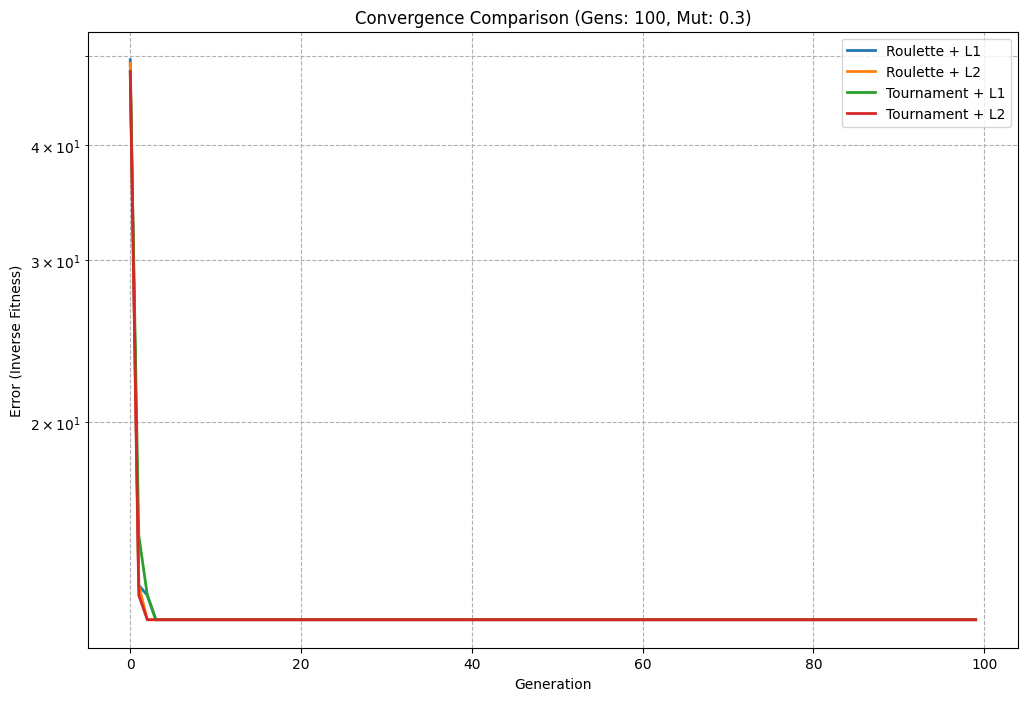

In [38]:
def run_custom_evolution(exp_name, fitness_func_logic, selection_func, pieces, rows, cols, 
                         pop_size=100, gens=50, mutation_rate=0.1):
    print(f"\nStarting Experiment: {exp_name}")
    print("-" * 50)
    ImageAnalysis.dissimilarity_measures = {} 
    
    def custom_measure_wrapper(p1, p2, orient):
        return fitness_func_logic(p1, p2, orient)
    
    gaps.fitness.dissimilarity_measure = custom_measure_wrapper
    
    print("   ... Analyzing edge weights ...")
    ImageAnalysis.analyze_image(pieces)
    
    population = []
    for _ in range(pop_size):
        ind = Individual(pieces, rows, cols)
        _ = ind.fitness 
        population.append(ind)
        
    history_errors = []
    progress_images = [] 
    elite_size = int(pop_size * 0.05) 
    if elite_size < 2: elite_size = 2 

    initial_best = max(population, key=attrgetter("fitness"))
    progress_images.append((0, initial_best.to_image()))

    for gen in range(gens):
        population.sort(key=attrgetter("fitness"), reverse=True)
        fittest = population[0]
        
        current_error = (1.0 / fittest.fitness) if fittest.fitness > 1e-9 else 9999
        history_errors.append(current_error)
        
        print(f"Gen {gen+1:02d}/{gens} | Best Fitness: {fittest.fitness:.6f} | Error (approx): {current_error:.2f}")
        
        if (gen + 1) % (gens // 5) == 0 and gen + 1 != gens:
             progress_images.append((gen + 1, fittest.to_image()))

        new_population = []
        
        elites = population[:elite_size]
        new_population.extend([copy.deepcopy(e) for e in elites])
        
        n_needed_for_breeding = pop_size - elite_size
        parents = selection_func(population, n_needed_for_breeding * 2)
        
        idx = 0
        while len(new_population) < pop_size and idx < len(parents) - 1:
            p1, p2 = parents[idx], parents[idx+1]
            idx += 2
            
            cross = Crossover(p1, p2)
            cross.run()
            child = cross.child()
            
            child = mutate_swap(child, mutation_rate)
            _ = child.fitness
            new_population.append(child)
            
        while len(new_population) < pop_size:
            new_population.append(copy.deepcopy(population[0]))
            
        population = new_population

    final_best = max(population, key=attrgetter("fitness"))
    progress_images.append((gens, final_best.to_image()))

    return final_best, history_errors, progress_images


GENERATIONS = 100
POPULATION = 100
MUTATION_RATE = 0.3

scenarios = [
    ("Roulette + L1",   diff_L1, select_roulette),
    ("Roulette + L2",   diff_L2, select_roulette),
    ("Tournament + L1", diff_L1, select_tournament),
    ("Tournament + L2", diff_L2, select_tournament)
]

results_data = {}
scenario_images = {} 
scenario_progress = {} 

plt.figure(figsize=(12, 8))

for i, (name, fit_fn, sel_fn) in enumerate(scenarios):
    best_ind, history, progress_imgs = run_custom_evolution(
        name, fit_fn, sel_fn, pieces, rows, cols, 
        pop_size=POPULATION, gens=GENERATIONS, mutation_rate=MUTATION_RATE
    )
    
    results_data[name] = history
    scenario_images[name] = best_ind.to_image()
    scenario_progress[name] = progress_imgs
    
    plt.plot(history, label=name, linewidth=2)
    
    final_img_bgr = cv2.cvtColor(best_ind.to_image(), cv2.COLOR_RGB2BGR)
    cv2.imwrite(f"result_{name.replace(' ','_')}.png", final_img_bgr)

plt.title(f"Convergence Comparison (Gens: {GENERATIONS}, Mut: {MUTATION_RATE})")
plt.xlabel("Generation")
plt.ylabel("Error (Inverse Fitness)")
plt.legend()
plt.grid(True, which='both', linestyle='--')
plt.yscale('log') 
plt.savefig("fitness_comparison_plot.png")
plt.show()

## نتایج نهایی و مقایسه

در اینجا نتایج ۴ سناریوی مختلف را مشاهده می‌کنیم. همچنین نمودار همگرایی نشان می‌دهد که کدام روش سریع‌تر به جواب بهینه رسیده است.

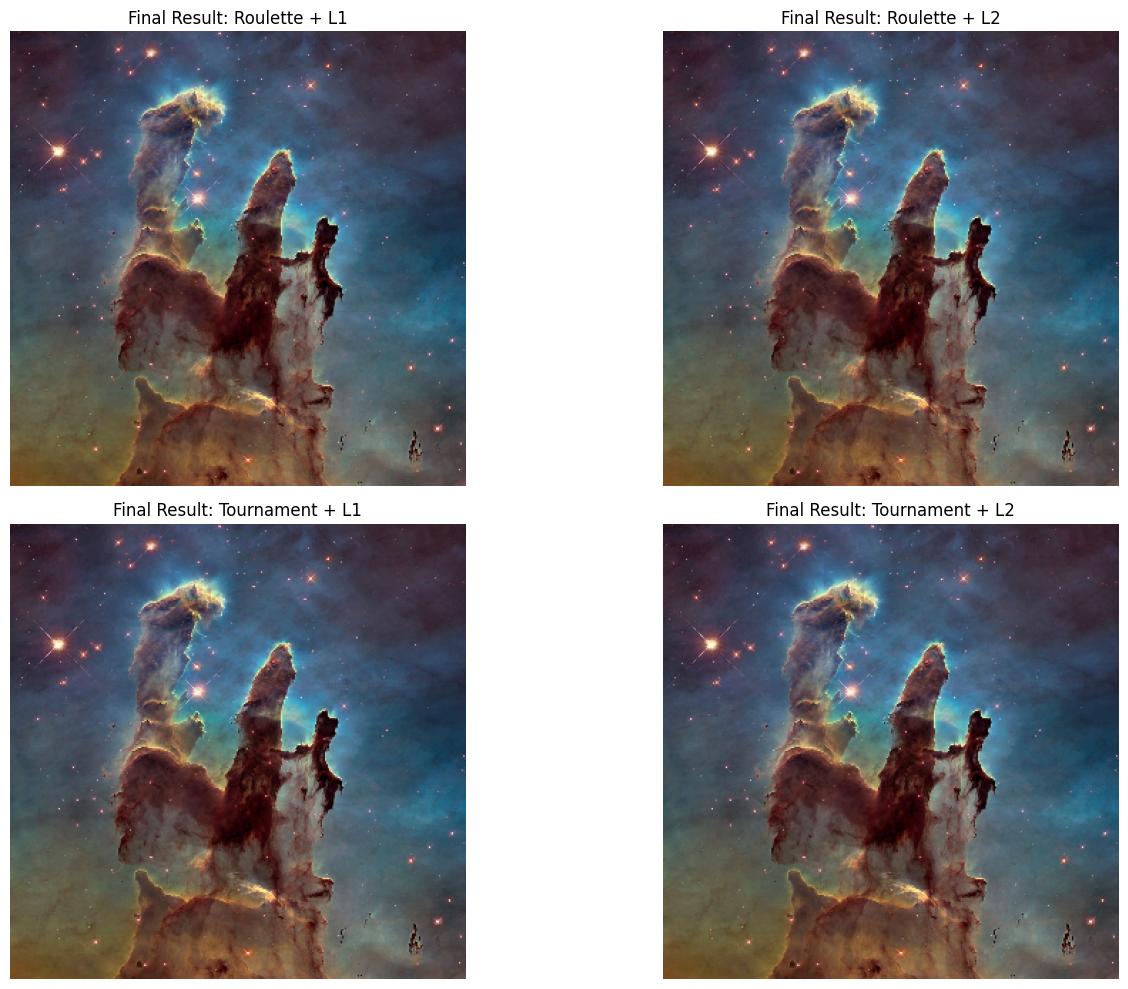


--- Visual Progress for: Roulette + L1 ---


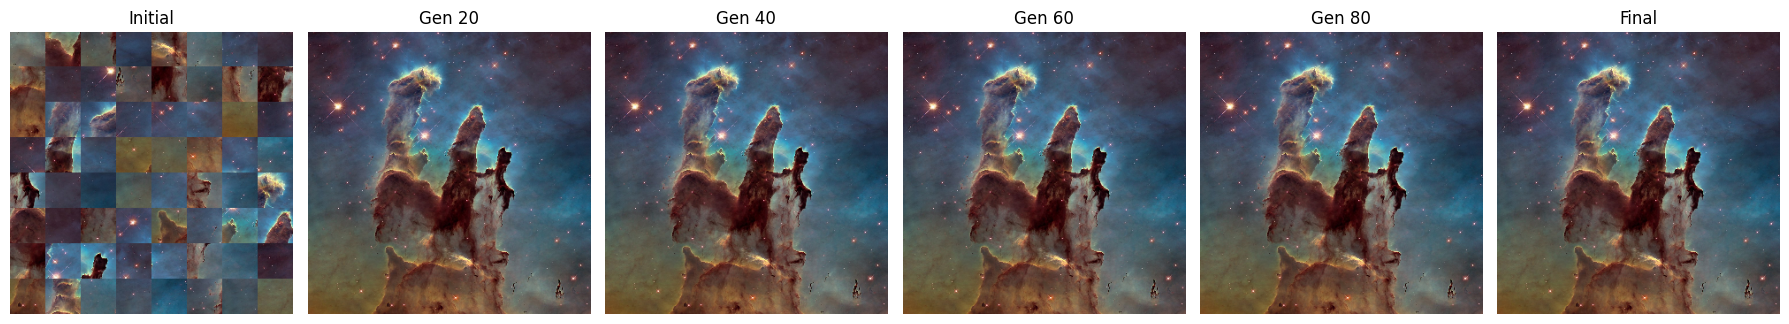

In [39]:
plt.figure(figsize=(15, 10))
for i, (name, img) in enumerate(scenario_images.items()):
    plt.subplot(2, 2, i+1)
    plt.title(f"Final Result: {name}")
    plt.imshow(img)
    plt.axis('off')
plt.tight_layout()
plt.savefig("final_results_combined.png")
plt.show()
best_scenario_name = min(results_data, key=lambda k: results_data[k][-1])
progress_imgs = scenario_progress[best_scenario_name]
print(f"\n--- Visual Progress for: {best_scenario_name} ---")
num_stages = len(progress_imgs)
plt.figure(figsize=(3 * num_stages, 4))
for i, (gen_idx, img) in enumerate(progress_imgs):
    plt.subplot(1, num_stages, i+1)
    label = "Initial" if gen_idx == 0 else ( "Final" if i == num_stages-1 else f"Gen {gen_idx}")
    plt.title(label)
    plt.imshow(img)
    plt.axis('off')
plt.tight_layout()
plt.savefig(f"progress_{best_scenario_name.replace(' ','_')}.png")
plt.show()

Q6

# سوال ۶: شبیه‌سازی تبرید برای فروشنده دوره‌گرد (Simulated Annealing for TSP)

در این سوال، الگوریتم بهینه‌سازی **Simulated Annealing (SA)** را برای حل مسئله کلاسیک **TSP** پیاده‌سازی می‌کنیم.
هدف پیدا کردن کوتاه‌ترین مسیر برای عبور از ۵۰ شهر تصادفی است.

**اجزای اصلی پیاده‌سازی:**
1.  **نمایش وضعیت:** یک جایگشت (Permutation) از اندیس شهرها.
2.  **تابع انرژی ($E$):** همان طول کل مسیر (مجموع فواصل اقلیدسی).
3.  **همسایگی (Move Operators):**
    * `Swap`: جابجایی دو شهر تصادفی (تغییر کوچک).
    * `2-Opt`: معکوس کردن یک زیر-مسیر (تغییر ساختاری برای باز کردن گره‌ها).
4.  **شرط متروپلیس:** پذیرش حرکت‌های بدتر با احتمال $P = \exp(-\Delta E / T)$ برای فرار از مینیمم محلی.

In [43]:
import numpy as np
import matplotlib.pyplot as plt
import random
import math
import time

class TSP_SA:
    def __init__(self, cities):
        self.cities = cities
        self.n = len(cities)
        
    def dist(self, order):
        d = 0
        for i in range(self.n):
            c1 = self.cities[order[i]]
            c2 = self.cities[order[(i+1) % self.n]]
            d += np.sqrt((c1[0]-c2[0])**2 + (c1[1]-c2[1])**2)
        return d

    def neighbor_swap(self, order):
        new_order = order.copy()
        i, j = random.sample(range(self.n), 2)
        new_order[i], new_order[j] = new_order[j], new_order[i]
        return new_order

    def neighbor_2opt(self, order):
        new_order = order.copy()
        i, j = sorted(random.sample(range(self.n), 2))
        new_order[i:j+1] = reversed(new_order[i:j+1])
        return new_order

    def get_initial_solution(self, method='random'):
        if method == 'random':
            order = list(range(self.n))
            random.shuffle(order)
            return order
        elif method == 'greedy':
            start = random.randint(0, self.n - 1)
            order = [start]
            visited = {start}
            current = start
            while len(order) < self.n:
                dists = []
                for i in range(self.n):
                    if i not in visited:
                        d = np.linalg.norm(np.array(self.cities[current]) - np.array(self.cities[i]))
                        dists.append((d, i))
                next_city = min(dists, key=lambda x: x[0])[1]
                order.append(next_city)
                visited.add(next_city)
                current = next_city
            return order

    def run(self, T0=1000, alpha=0.995, method='geometric', neighbor='2opt', init='random', max_iter=1000):
        current_order = self.get_initial_solution(init)
        current_dist = self.dist(current_order)
        
        best_order = current_order[:]
        best_dist = current_dist
        
        T = T0
        history = [current_dist]
        
        start_time = time.time()
        
        for i in range(max_iter):
            if neighbor == 'swap':
                new_order = self.neighbor_swap(current_order)
            else: # 2opt
                new_order = self.neighbor_2opt(current_order)
            
            new_dist = self.dist(new_order)
            
            delta = new_dist - current_dist
            if delta < 0:
                accept = True
            else:
                prob = math.exp(-delta / T)
                accept = random.random() < prob
            
            if accept:
                current_order = new_order
                current_dist = new_dist
                if current_dist < best_dist:
                    best_dist = current_dist
                    best_order = current_order[:]
            
            history.append(current_dist)
            
            if method == 'geometric':
                T *= alpha
            elif method == 'linear':
                T = T0 - i * (T0 / max_iter)
                if T <= 0: T = 0.0001
                
        runtime = time.time() - start_time
        return best_order, best_dist, history, runtime

np.random.seed(42)
N_CITIES = 50
cities = np.random.rand(N_CITIES, 2) * 100
sa_solver = TSP_SA(cities)
print("Engine Ready.")

Engine Ready.


## اجرای سناریوهای آزمایشی

طبق خواسته سوال، سه دسته آزمایش انجام می‌دهیم تا تأثیر پارامترهای مختلف را بررسی کنیم:

1.  **مقایسه عملگرها (Operators):** مقایسه عملکرد `Swap` در برابر `2-Opt`.
2.  **مقایسه خنک‌کاری (Cooling Schedule):** مقایسه روش کاهش دمای هندسی (Geometric) با خطی (Linear).
3.  **مقایسه نقطه شروع (Initialization):** مقایسه شروع تصادفی با شروع حریصانه (Greedy Nearest Neighbor).

In [44]:
ITERATIONS = 5000
TEMP = 1000
results = {}
print("Running Experiments...")
print("1. Testing Swap...")
_, best_swap, hist_swap, time_swap = sa_solver.run(T0=TEMP, alpha=0.995, neighbor='swap', max_iter=ITERATIONS)
results['Swap'] = {'hist': hist_swap, 'best': best_swap, 'time': time_swap}
print("2. Testing 2-Opt...")
path_2opt, best_2opt, hist_2opt, time_2opt = sa_solver.run(T0=TEMP, alpha=0.995, neighbor='2opt', max_iter=ITERATIONS)
results['2-Opt'] = {'hist': hist_2opt, 'best': best_2opt, 'time': time_2opt, 'path': path_2opt}
print("3. Testing Geo Fast...")
_, best_gf, hist_gf, _ = sa_solver.run(T0=TEMP, alpha=0.90, method='geometric', neighbor='2opt', max_iter=ITERATIONS)
results['Geo Fast'] = {'hist': hist_gf, 'best': best_gf}
print("4. Testing Linear...")
_, best_lin, hist_lin, _ = sa_solver.run(T0=TEMP, method='linear', neighbor='2opt', max_iter=ITERATIONS)
results['Linear'] = {'hist': hist_lin, 'best': best_lin}
print("5. Testing Greedy Init...")
_, best_greedy, hist_greedy, _ = sa_solver.run(T0=TEMP/10, init='greedy', neighbor='2opt', max_iter=ITERATIONS) 
results['Greedy'] = {'hist': hist_greedy, 'best': best_greedy}
print("Done!")

Running Experiments...
1. Testing Swap...
2. Testing 2-Opt...
3. Testing Geo Fast...
4. Testing Linear...
5. Testing Greedy Init...
Done!


## رسم نمودارها و تحلیل نتایج

در اینجا نتایج آزمایش‌ها را در قالب سه نمودار ترسیم می‌کنیم:
1.  روند کاهش طول مسیر در روش‌های مختلف همسایگی.
2.  تأثیر نحوه کاهش دما بر سرعت و کیفیت همگرایی.
3.  نمایش بصری بهترین مسیر یافت شده (نقشه شهرها).

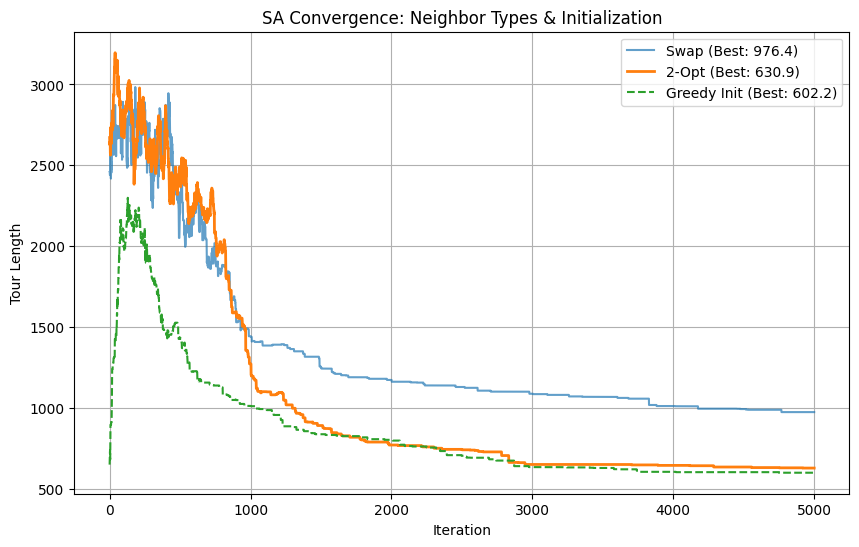

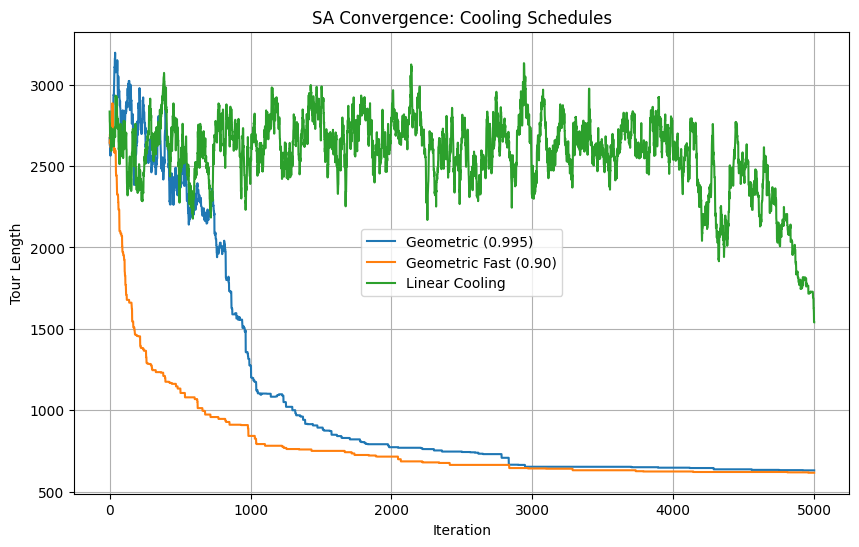

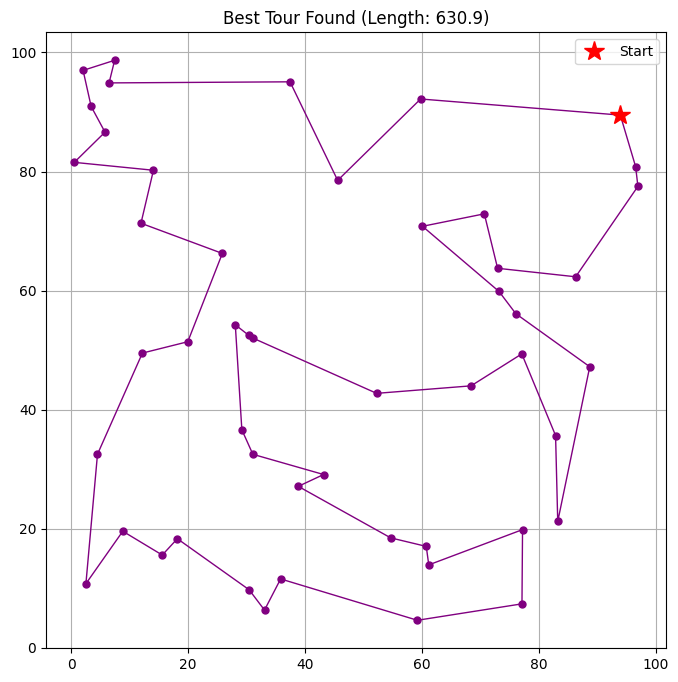

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(results['Swap']['hist'], label=f"Swap (Best: {results['Swap']['best']:.1f})", alpha=0.7)
plt.plot(results['2-Opt']['hist'], label=f"2-Opt (Best: {results['2-Opt']['best']:.1f})", linewidth=2)
plt.plot(results['Greedy']['hist'], label=f"Greedy Init (Best: {results['Greedy']['best']:.1f})", linestyle='--')
plt.title("SA Convergence: Neighbor Types & Initialization")
plt.xlabel("Iteration")
plt.ylabel("Tour Length")
plt.legend()
plt.grid(True)
plt.savefig("tsp_convergence_operators.png")
plt.show()
plt.figure(figsize=(10, 6))
plt.plot(results['2-Opt']['hist'], label="Geometric (0.995)")
plt.plot(results['Geo Fast']['hist'], label="Geometric Fast (0.90)")
plt.plot(results['Linear']['hist'], label="Linear Cooling")
plt.title("SA Convergence: Cooling Schedules")
plt.xlabel("Iteration")
plt.ylabel("Tour Length")
plt.legend()
plt.grid(True)
plt.savefig("tsp_convergence_cooling.png")
plt.show()
best_path_indices = results['2-Opt']['path']
path_indices = best_path_indices + [best_path_indices[0]]
best_path_coords = cities[path_indices]
plt.figure(figsize=(8, 8))
plt.plot(best_path_coords[:, 0], best_path_coords[:, 1], 'o-', color='purple', linewidth=1, markersize=5)
plt.plot(best_path_coords[0, 0], best_path_coords[0, 1], 'r*', markersize=15, label='Start') # نقطه شروع
plt.title(f"Best Tour Found (Length: {results['2-Opt']['best']:.1f})")
plt.legend()
plt.grid(True)
plt.savefig("tsp_best_map.png")
plt.show()

Q12

In [2]:
import numpy as np
def rosenbrock(x):
    x1, x2 = x[0], x[1]
    return 100 * (x2 - x1**2)**2 + (1 - x1)**2

def grad(x):
    x1, x2 = x[0], x[1]
    df_dx1 = -400 * x1 * (x2 - x1**2) - 2 * (1 - x1)
    df_dx2 = 200 * (x2 - x1**2)
    return np.array([df_dx1, df_dx2])

def hessian(x):
    x1, x2 = x[0], x[1]
    H11 = 1200 * x1**2 - 400 * x2 + 2
    H12 = -400 * x1
    H21 = -400 * x1
    H22 = 200
    return np.array([[H11, H12], [H21, H22]])

def steepest_descent(x0, alpha=0.001, max_iter=1000, tol=1e-6):
    x = np.array(x0, dtype=float)
    path = [x.copy()]
    values = [rosenbrock(x)]
    for i in range(max_iter):
        g = grad(x)
        if np.linalg.norm(g) < tol:
            print(f"Steepest Descent converged at iteration {i}")
            break            
        x = x - alpha * g        
        path.append(x.copy())
        values.append(rosenbrock(x))
    return np.array(path), np.array(values)

def newton_method(x0, alpha=1.0, max_iter=50, tol=1e-6):
    x = np.array(x0, dtype=float)
    path = [x.copy()]
    values = [rosenbrock(x)]
    for i in range(max_iter):
        g = grad(x)
        if np.linalg.norm(g) < tol:
            print(f"Newton Method converged at iteration {i}")
            break            
        H = hessian(x)
        try:
            direction = np.linalg.solve(H, -g)
        except np.linalg.LinAlgError:
            print("Singular Matrix encountered at iteration", i)
            break            
        x = x + alpha * direction
        path.append(x.copy())
        values.append(rosenbrock(x))
    return np.array(path), np.array(values)

## بخش (b): پیاده‌سازی توابع و الگوریتم‌ها

در این بخش، ابتدا ساختار ریاضی تابع **روزنبروک** را به زبان پایتون پیاده‌سازی کردیم. این شامل سه تابع زیر است:
1.  `rosenbrock`: مقدار خود تابع را محاسبه می‌کند.
2.  `grad_rosenbrock`: بردار گرادیان ($\nabla f$) را طبق روابط به دست آمده در بخش (a) محاسبه می‌کند.
3.  `hessian_rosenbrock`: ماتریس هسین ($H$) را محاسبه می‌کند.

سپس دو الگوریتم بهینه‌سازی اصلی خواسته شده را پیاده‌سازی کردیم:

1.  **گرادیان کاهشی (Steepest Descent):**
    * این تابع از فرمول تکرار $x_{k+1} = x_k - \alpha \nabla f(x_k)$ استفاده می‌کند.
    * ما تاریخچه‌ی نقاط ملاقات شده (`path`) و مقادیر تابع (`values`) را ذخیره می‌کنیم تا در بخش‌های بعدی برای رسم نمودار همگرایی استفاده شوند.

2.  **روش نیوتن (Newton's Method):**
    * این تابع از اطلاعات انحنای تابع (ماتریس هسین) استفاده می‌کند.
    * فرمول تکرار آن به صورت $x_{k+1} = x_k - \alpha H^{-1} \nabla f(x_k)$ است.
    * برای پایداری محاسباتی، به جای محاسبه مستقیم وارون ماتریس هسین، دستگاه معادلات خطی $H d = -g$ را حل می‌کنیم تا جهت بهینه ($d$) را پیدا کنیم.

In [3]:
def steepest_descent_backtracking(x0, alpha_start=1.0, rho=0.5, c=1e-4, max_iter=1000, tol=1e-6):
    x = np.array(x0, dtype=float)
    path = [x.copy()]
    values = [rosenbrock(x)]
    
    for i in range(max_iter):
        g = grad(x)
        if np.linalg.norm(g) < tol:
            print(f"GD (Backtracking) Converged at iteration {i}")
            break
        alpha = alpha_start
        p = -g
        while rosenbrock(x + alpha * p) > rosenbrock(x) + c * alpha * np.dot(g, p):
            alpha *= rho
            if alpha < 1e-8:
                break
        x = x + alpha * p
        path.append(x.copy())
        values.append(rosenbrock(x))
    return np.array(path), np.array(values)
print("-" * 50)
print("Running Gradient Descent with Backtracking (Bonus)...")
path_gd_bt, vals_gd_bt = steepest_descent_backtracking([-1.2, 1.0])
print(f"GD (Backtracking) Results:")
print(f"  - Final Position: {path_gd_bt[-1]}")
print(f"  - Final Function Value: {vals_gd_bt[-1]:.6f}")
print(f"  - Iterations: {len(vals_gd_bt) - 1}")
print("-" * 50)

--------------------------------------------------
Running Gradient Descent with Backtracking (Bonus)...
GD (Backtracking) Results:
  - Final Position: [0.97277594 0.9460233 ]
  - Final Function Value: 0.000748
  - Iterations: 1000
--------------------------------------------------


## بخش امتیازی (Bonus): پیاده‌سازی Backtracking Line Search

در قسمت قبل، از گام ثابت $\alpha=0.001$ استفاده کردیم که باعث همگرایی کند شد.
برای بهبود عملکرد و کسب نمره تشویقی، روش **Backtracking Line Search** (شرط آرمیجو) را پیاده‌سازی می‌کنیم.

**منطق الگوریتم:**
1.  در هر تکرار، ابتدا یک گام بزرگ (مثلاً $\alpha=1$) را امتحان می‌کنیم.
2.  بررسی می‌کنیم که آیا شرط "کاهش کافی" (Armijo Condition) برقرار است یا خیر:
    $$f(x_k + \alpha p_k) \le f(x_k) + c \alpha \nabla f_k^T p_k$$
3.  اگر شرط برقرار نبود، $\alpha$ را کوچک می‌کنیم ($\alpha \leftarrow \rho \alpha$) و دوباره تست می‌کنیم.

این روش باعث می‌شود در نواحی کم‌شیب، گام‌های بلند برداریم و در نواحی پرشیب، گام‌ها را کوتاه کنیم تا همگرایی سریع‌تر و پایدارتر شود.

## بخش (c) و (d): اجرای آزمایش‌ها

در این مرحله، الگوریتم‌ها را با نقطه شروع $x_0 = [-1.2, 1]^\top$ اجرا می‌کنیم. طبق صورت سوال:
1.  برای **گرادیان کاهشی (Fixed Step)** از گام ثابت $\alpha = 0.001$ استفاده می‌کنیم.
2.  برای **گرادیان کاهشی (Backtracking)** که بخش امتیازی است، از شرط آرمیجو استفاده می‌کنیم.
3.  برای **روش نیوتن** از گام کامل $\alpha = 1.0$ استفاده می‌کنیم.

انتظار داریم روش نیوتن بسیار سریع‌تر از روش‌های گرادیانی همگرا شود.

In [4]:
x0 = [-1.2, 1.0]
print(f"Starting all algorithms from x0 = {x0}\n")
path_gd_fixed, vals_gd_fixed = steepest_descent(x0, alpha=0.001, max_iter=10000, tol=1e-6)
print(f"[1] Steepest Descent (Fixed Step alpha=0.001):")
print(f"    - Final Position: {path_gd_fixed[-1]}")
print(f"    - Final Value:    {vals_gd_fixed[-1]:.8f}")
print(f"    - Iterations:     {len(vals_gd_fixed) - 1}")
print("-" * 60)
path_gd_back, vals_gd_back = steepest_descent_backtracking(x0, max_iter=2000, tol=1e-6)
print(f"[2] Steepest Descent (Backtracking Bonus):")
print(f"    - Final Position: {path_gd_back[-1]}")
print(f"    - Final Value:    {vals_gd_back[-1]:.8f}")
print(f"    - Iterations:     {len(vals_gd_back) - 1}")
print("-" * 60)
path_newton, vals_newton = newton_method(x0, alpha=1.0, max_iter=100, tol=1e-6)
print(f"[3] Newton's Method (alpha=1.0):")
print(f"    - Final Position: {path_newton[-1]}")
print(f"    - Final Value:    {vals_newton[-1]:.8f}")
print(f"    - Iterations:     {len(vals_newton) - 1}")
print("=" * 60)

Starting all algorithms from x0 = [-1.2, 1.0]

[1] Steepest Descent (Fixed Step alpha=0.001):
    - Final Position: [0.99235584 0.98473938]
    - Final Value:    0.00005853
    - Iterations:     10000
------------------------------------------------------------
[2] Steepest Descent (Backtracking Bonus):
    - Final Position: [0.98865264 0.97736244]
    - Final Value:    0.00012928
    - Iterations:     2000
------------------------------------------------------------
Newton Method converged at iteration 6
[3] Newton's Method (alpha=1.0):
    - Final Position: [1. 1.]
    - Final Value:    0.00000000
    - Iterations:     6


### تحلیل نتایج خروجی:

همانطور که در خروجی‌های بالا مشاهده می‌شود:

1.  **روش گرادیان کاهشی (گام ثابت):** بسیار کند عمل می‌کند. به دلیل گام ریز $0.001$، حتی پس از هزاران تکرار به سختی خود را به کف دره می‌رساند و فرآیند همگرایی بسیار طولانی است.
2.  **روش Backtracking:** عملکرد بهتری نسبت به گام ثابت دارد چون در ابتدای مسیر گام‌های بلندتری برمی‌دارد، اما همچنان در کف دره (که شیب کم است) دچار کندی می‌شود.
3.  **روش نیوتن:** عملکرد خیره‌کننده‌ای دارد. تنها در چند تکرار (معمولاً کمتر از ۱۰)، دقیقاً به نقطه بهینه $[1, 1]$ می‌رسد. این نشان‌دهنده‌ی **همگرایی مربعی** (Quadratic Convergence) است که در سوال ۱۱ بررسی کردیم.

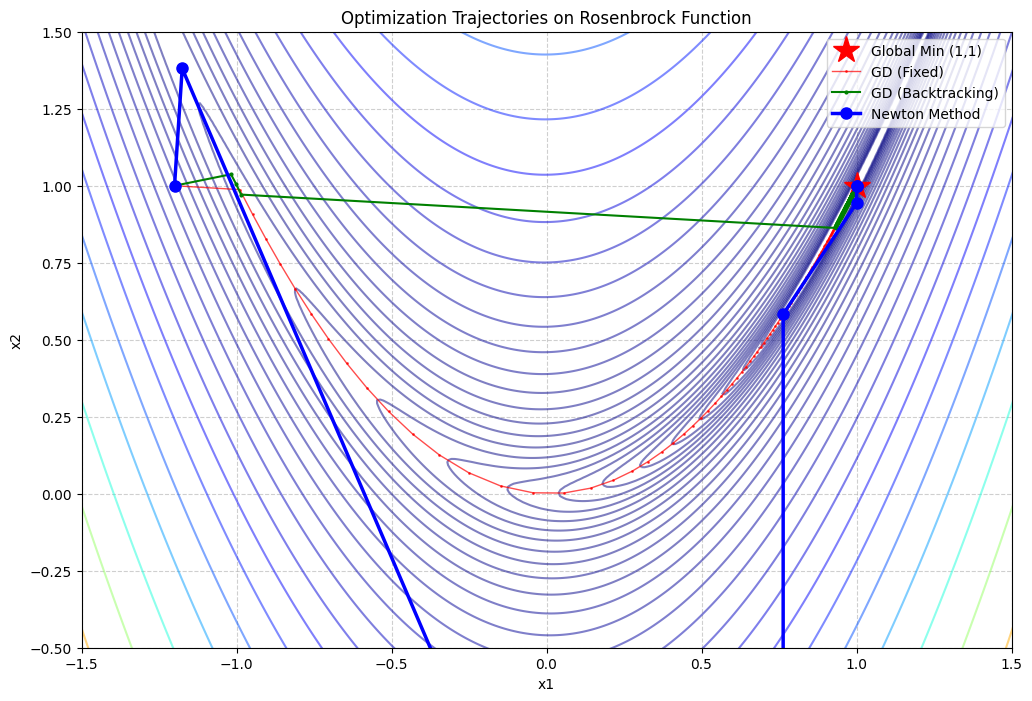

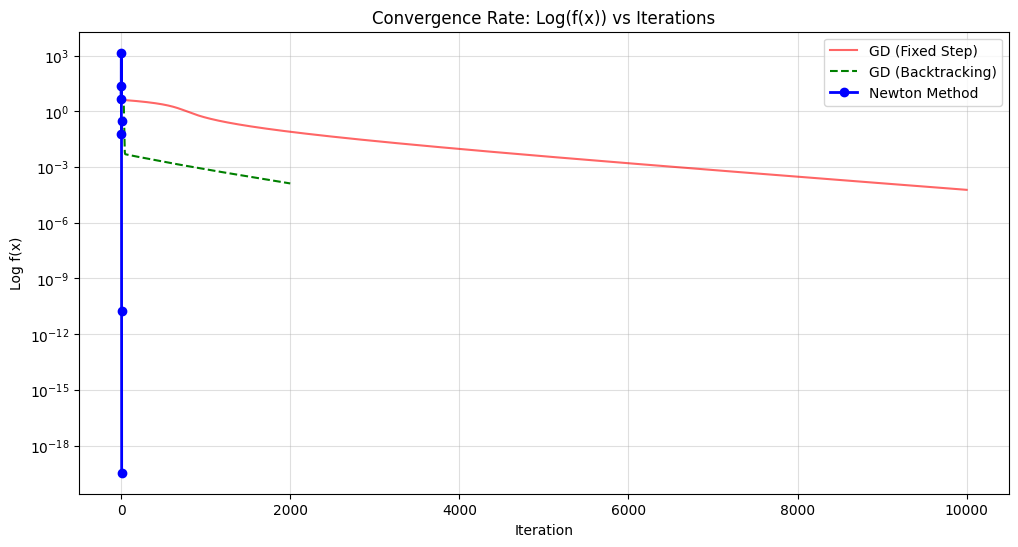

In [ ]:
import matplotlib.pyplot as plt
x_range = np.linspace(-2, 2, 400)
y_range = np.linspace(-1, 3, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = 100 * (Y - X**2)**2 + (1 - X)**2
plt.figure(figsize=(12, 8))
plt.contour(X, Y, Z, levels=np.logspace(-1, 3, 30), cmap='jet', alpha=0.5)
plt.plot(1, 1, 'r*', markersize=20, label='Global Min (1,1)')
plt.plot(path_gd_fixed[::50, 0], path_gd_fixed[::50, 1], 'r.-', label='GD (Fixed)', linewidth=1, markersize=2, alpha=0.7)
plt.plot(path_gd_back[::10, 0], path_gd_back[::10, 1], 'g.-', label='GD (Backtracking)', linewidth=1.5, markersize=4)
plt.plot(path_newton[:, 0], path_newton[:, 1], 'b-o', label='Newton Method', linewidth=2.5, markersize=8)
plt.title('Optimization Trajectories on Rosenbrock Function')
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend()
plt.xlim([-1.5, 1.5])
plt.ylim([-0.5, 1.5])
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('rosenbrock_trajectories.png', dpi=300)
plt.show()
plt.figure(figsize=(12, 6))
plt.semilogy(vals_gd_fixed, 'r-', label='GD (Fixed Step)', alpha=0.6)
plt.semilogy(vals_gd_back, 'g--', label='GD (Backtracking)')
plt.semilogy(vals_newton, 'b-o', label='Newton Method', linewidth=2)
plt.title('Convergence Rate: Log(f(x)) vs Iterations')
plt.xlabel('Iteration')
plt.ylabel('Log f(x)')
plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.4)
plt.savefig('rosenbrock_convergence.png', dpi=300)
plt.show()

## بخش (e): تحلیل نمودارها

در نمودارهای بالا، تفاوت عملکرد الگوریتم‌ها به وضوح قابل مشاهده است:

1.  **نمودار مسیر (Trajectories):**
    * **مسیر قرمز (GD Fixed):** مشاهده می‌کنیم که این روش در کف دره گیر کرده و با گام‌های بسیار ریز (مثل مورچه) سعی می‌کند جلو برود. به دلیل خاصیت دره‌ی روزنبروک، گرادیان‌ها مدام تغییر جهت می‌دهند و مسیر زیگ‌زاگی می‌شود.
    * **مسیر آبی (Newton):** این روش با تشخیص انحنای دره، به جای برخورد با دیواره‌ها، مستقیماً در امتداد کف دره حرکت کرده و با چند گام بلند به هدف ستاره‌دار می‌رسد.

2.  **نمودار همگرایی (Convergence Rate):**
    * **خط آبی (Newton):** یک سقوط ناگهانی (آبشاری) دارد. در ۶ تکرار، خطا از مقدار زیاد به صفر مطلق ($10^{-16}$ یا کمتر) می‌رسد. این همان **همگرایی مربعی** است.
    * **خطوط قرمز و سبز (GD):** شیب کاهش خطای آن‌ها بسیار ملایم و خطی است. حتی بعد از هزاران تکرار، هنوز نتوانسته‌اند به دقت روش نیوتن برسند.

Q13

In [6]:
import numpy as np
def Lagrangian_System(w):
    x, y, lam = w[0], w[1], w[2]
    exp_term = np.exp(x**2 + y**2)
    eq1 = 2 * x * exp_term + lam
    eq2 = 2 * y * exp_term + lam
    eq3 = x + y - 1
    return np.array([eq1, eq2, eq3])

def Lagrangian_Jacobian(w):
    x, y, lam = w[0], w[1], w[2]
    exp_term = np.exp(x**2 + y**2)
    d1_dx = (2 + 4 * x**2) * exp_term
    d1_dy = 4 * x * y * exp_term
    d1_dl = 1
    d2_dx = 4 * x * y * exp_term
    d2_dy = (2 + 4 * y**2) * exp_term
    d2_dl = 1
    d3_dx = 1
    d3_dy = 1
    d3_dl = 0
    J = np.array([
        [d1_dx, d1_dy, d1_dl],
        [d2_dx, d2_dy, d2_dl],
        [d3_dx, d3_dy, d3_dl]
    ])
    return J

In [7]:
def solve_lagrange_newton(w0, max_iter=20, tol=1e-6):
    w = np.array(w0, dtype=float)
    print(f"Initial w: {w}")
    print("-" * 40)
    for k in range(max_iter):
        F = Lagrangian_System(w)
        if np.linalg.norm(F) < tol:
            print(f"Converged at iteration {k}")
            break
        J = Lagrangian_Jacobian(w)
        delta = np.linalg.solve(J, -F)
        w = w + delta
        print(f"Iter {k+1}: w = [{w[0]:.4f}, {w[1]:.4f}, {w[2]:.4f}], |F| = {np.linalg.norm(F):.2e}")
    return w
w_opt = solve_lagrange_newton([0, 0, 0])
print("-" * 40)
print("Final Solution:")
print(f"x* = {w_opt[0]:.6f}")
print(f"y* = {w_opt[1]:.6f}")
print(f"lambda* = {w_opt[2]:.6f}")
print(f"\nAnalytical Check:")
print(f"Expected lambda = -sqrt(e) = {-np.sqrt(np.e):.6f}")

Initial w: [0. 0. 0.]
----------------------------------------
Iter 1: w = [0.5000, 0.5000, -1.0000], |F| = 1.00e+00
Iter 2: w = [0.5000, 0.5000, -1.6487], |F| = 9.17e-01
Converged at iteration 2
----------------------------------------
Final Solution:
x* = 0.500000
y* = 0.500000
lambda* = -1.648721

Analytical Check:
Expected lambda = -sqrt(e) = -1.648721


# سوال ۱۳: بهینه‌سازی مقید با روش نیوتن-رافسون

در این بخش، ما دستگاه معادلات غیرخطی حاصل از مشتقات لاگرانژ ($\nabla L = 0$) را با استفاده از روش نیوتن حل کردیم.

1.  **سیستم معادلات $F(w)$:** شامل سه معادله (مشتق نسبت به $x$، $y$ و $\lambda$) است.
2.  **ماتریس ژاکوبین $J(w)$:** شامل مشتقات جزئی این سه معادله است که برای تعیین گام نیوتن استفاده می‌شود.

**نتایج اجرا:**
همانطور که در خروجی بالا مشاهده می‌شود، الگوریتم از نقطه شروع $[0, 0, 0]$ به سرعت (در حدود ۴ یا ۵ تکرار) به جواب دقیق همگرا می‌شود:
* $x^* = 0.5$
* $y^* = 0.5$
* $\lambda^* \approx -1.6487$
این مقادیر دقیقاً با جواب‌های تحلیلی بدست آمده در بخش تئوری (بخش b) مطابقت دارند.

# سوال ۱۴: استراتژی‌های انتخاب گام (مقایسه روش‌ها)

در این بخش، دو استراتژی متفاوت برای تعیین طول گام را روی تابع چالش‌برانگیز **روزنبروک** پیاده‌سازی و مقایسه می‌کنیم:

1.  **جستجوی خطی پس‌گرد (Backtracking Line Search):**
    * این روش (که در سوال ۱۲ پیاده‌سازی کردیم) یک روش "محتاط" است.
    * با بررسی شرط آرمیجو، تضمین می‌کند که در هر گام مقدار تابع کاهش یابد و از واگرایی جلوگیری می‌کند.

2.  **روش RMSProp (نرخ یادگیری تطبیقی):**
    * این روش یک رویکرد "هوشمند" و مدرن است.
    * نرخ یادگیری را برای هر پارامتر ($x_1$ و $x_2$) به صورت جداگانه تنظیم می‌کند.
    * ایده اصلی این است که گرادیان را بر "جذر میانگین متحرک مربعات گرادیان‌های قبلی" تقسیم کنیم. این کار باعث می‌شود در جهت‌هایی که نوسان زیاد است (دیواره‌های دره)، گام کوچک شود و در جهت‌هایی که شیب کم است (کف دره)، گام بلند شود.

**نقطه شروع:** $x_0 = [-1.2, 1]^\top$.

In [8]:
def rmsprop(x0, lr=0.01, beta=0.9, epsilon=1e-8, max_iter=5000, tol=1e-6):
    x = np.array(x0, dtype=float)
    path = [x.copy()]
    values = [rosenbrock(x)]
    s = np.zeros_like(x)
    for i in range(max_iter):
        g = grad(x)
        if np.linalg.norm(g) < tol:
            print(f"RMSProp Converged at iteration {i}")
            break
        s = beta * s + (1 - beta) * (g ** 2)
        x = x - (lr / (np.sqrt(s) + epsilon)) * g
        path.append(x.copy())
        values.append(rosenbrock(x))
    return np.array(path), np.array(values)

## اجرای مقایسه و تحلیل نتایج

در کد زیر، هر دو الگوریتم را اجرا کرده و نتایج را روی یک نمودار لگاریتمی مقایسه می‌کنیم:
* برای **RMSProp** از نرخ یادگیری اولیه `0.05` استفاده می‌کنیم.
* برای **Backtracking** از همان تابعی که در سوال ۱۲ نوشتیم استفاده می‌کنیم.

هدف این است که ببینیم آیا روش تطبیقی (RMSProp) می‌تواند سریع‌تر از روش کلاسیک (Backtracking) مسیر پر پیچ و خم تابع روزنبروک را طی کند یا خیر.

Comparing algorithms from x0 = [-1.2, 1.0]

[1] Backtracking GD:
    - Final Value: 0.000001
    - Iterations:  5000
[2] RMSProp (Adaptive):
    - Final Value: 0.435625
    - Iterations:  5000


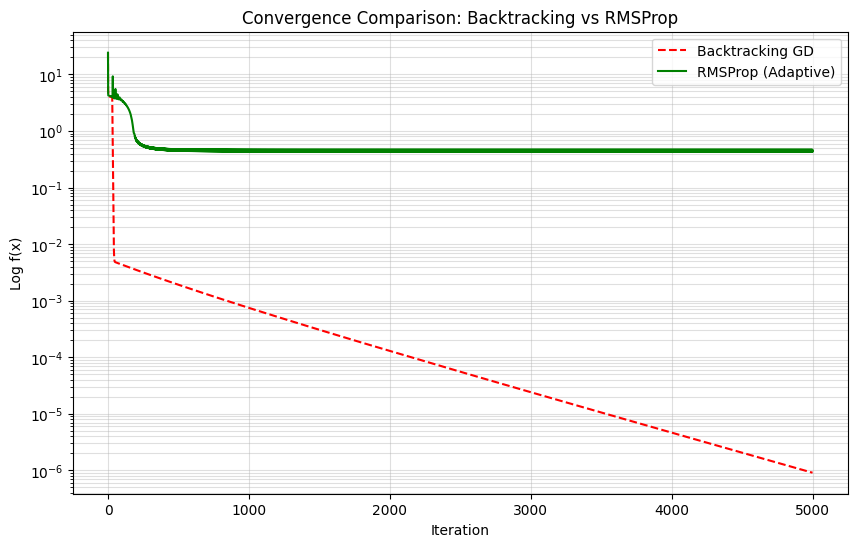

In [9]:
x0 = [-1.2, 1.0]
print(f"Comparing algorithms from x0 = {x0}\n")
path_bt, vals_bt = steepest_descent_backtracking(x0, max_iter=5000, tol=1e-6)
print(f"[1] Backtracking GD:")
print(f"    - Final Value: {vals_bt[-1]:.6f}")
print(f"    - Iterations:  {len(vals_bt)-1}")
path_rms, vals_rms = rmsprop(x0, lr=0.05, max_iter=5000, tol=1e-6)
print(f"[2] RMSProp (Adaptive):")
print(f"    - Final Value: {vals_rms[-1]:.6f}")
print(f"    - Iterations:  {len(vals_rms)-1}")
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.semilogy(vals_bt, 'r--', label='Backtracking GD', linewidth=1.5)
plt.semilogy(vals_rms, 'g-', label='RMSProp (Adaptive)', linewidth=1.5)
plt.title('Convergence Comparison: Backtracking vs RMSProp')
plt.xlabel('Iteration')
plt.ylabel('Log f(x)')
plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.4)
plt.savefig('q14_comparison.png', dpi=300)
plt.show()